<a href="https://colab.research.google.com/github/genet-sql-bi/olist-ecommerce-powerbi-dashboard/blob/main/python/olist_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Brazilian E-Commerce Analytics Project**

# Project Overview

This project analyzes the Brazilian E-commerce (Olist) dataset using PostgreSQL, Python, Google Colab, and Power BI.

```
The objective is to answer important business questions related to:

- Sales performance
- Customer behavior
- Delivery and logistics
- Product reviews
- Shipping cost analysis
```

The project combines SQL querying, Python data analysis, data visualization, and Power BI dashboard development to generate business insights.

----------------------------------------

# Tools & Technologies

```
- PostgreSQL
- Python
- Pandas
- Matplotlib
- Google Colab
- Power BI
```

----------------------------------------
## Project Workflow

1. Load and connect PostgreSQL data  
2. Analyze business questions using SQL  
3. Process data with Python and Pandas  
4. Create visualizations with Matplotlib  
5. Build interactive dashboards in Power BI
----------------------------------------

# Dataset

The dataset contains information about:

```
- Orders
- Customers
- Sellers
- Products
- Payments
- Reviews
- Freight and logistics
```


----------------------------------------
# Business Questions

This project answers 10 business questions, including:

1. Top-selling categories  
2. Highest revenue states  
3. Top-performing sellers  
4. Popular payment methods  
5. Delivery performance  
6. Review analysis  
7. Average order value  
8. Customer distribution  
9. Freight cost analysis  
10. Shipping economics

## Install Required Libraries

The following libraries are used to connect PostgreSQL with Python in Google Colab:

- psycopg2-binary → PostgreSQL connector
- SQLAlchemy → Database connection engine

In [128]:
!pip install psycopg2-binary sqlalchemy

In [129]:
import os
from getpass import getpass

os.environ["DB_USER"] = "postgres"
os.environ["DB_PASSWORD"] = getpass("PostgreSQL password: ")


PostgreSQL password: ··········


## Database Connection

This section connects Google Colab to the PostgreSQL database using SQLAlchemy and Psycopg2.

The connection is used to load e-commerce data into Pandas DataFrames for SQL analysis and visualization.

A test query is executed to confirm the database connection and preview customer data.

In [130]:
from sqlalchemy import create_engine
import pandas as pd

# PostgreSQL credentials
import os

username = os.getenv("DB_USER")
password = os.getenv("DB_PASSWORD")

# ngrok forwarding details
host = "YOUR_NGROK_HOST"
port = "YOUR_NGROK_PORT"            # the number after the colon

# Database name
database = "Brazilian_Ecom"

# Create connection
engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}",
    pool_pre_ping=True
)

# Test query
query = "SELECT * FROM customers LIMIT 5;"

# Load into pandas
df = pd.read_sql(query, engine)

# Show result
print(df)

                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  


## Business Question 1: What are the top-selling product categories?

This query identifies the top product categories based on total orders and total revenue.

In [131]:
query = """
SELECT
    ct.product_category_name_english AS category,

    COUNT(oi.order_id) AS total_orders,

    ROUND(SUM(oi.price)::numeric, 2) AS total_revenue

FROM order_items oi

JOIN products p
ON oi.product_id = p.product_id

JOIN category_translation ct
ON p.product_category_name = ct.product_category_name

GROUP BY category

ORDER BY total_revenue DESC

LIMIT 10;
"""

top_categories = pd.read_sql(query, engine)

top_categories

,category,total_orders,total_revenue
0,health_beauty,9670,1258681.34
1,watches_gifts,5991,1205005.68
2,bed_bath_table,11115,1036988.68
3,sports_leisure,8641,988048.97
4,computers_accessories,7827,911954.32
5,furniture_decor,8334,729762.49
6,cool_stuff,3796,635290.85
7,housewares,6964,632248.66
8,auto,4235,592720.11
9,garden_tools,4347,485256.46


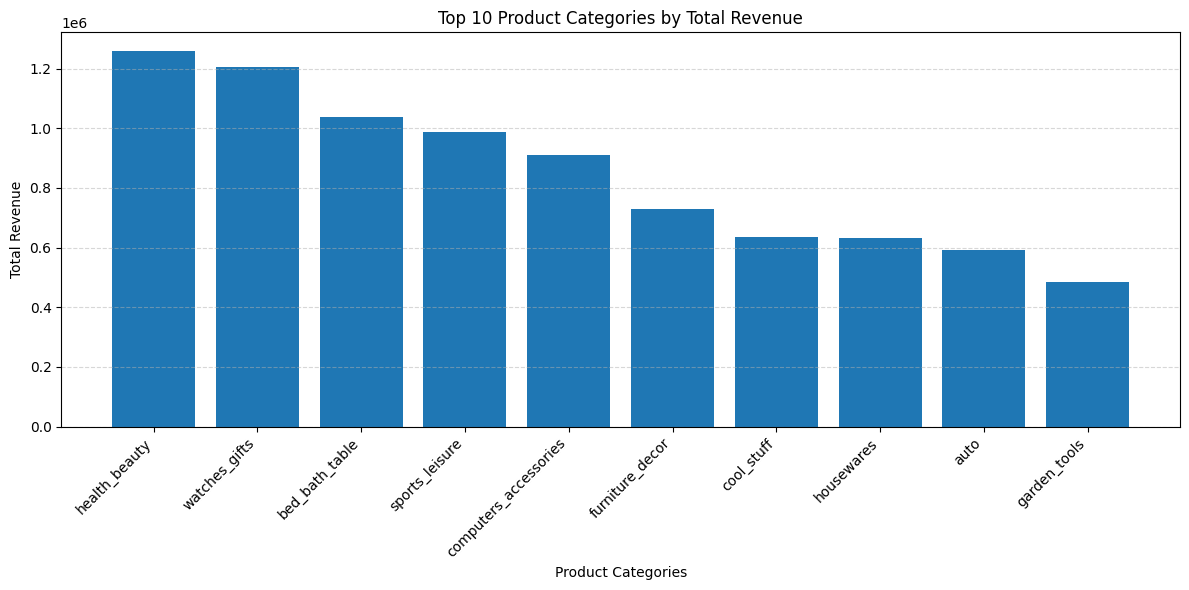

In [132]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.bar(
    top_categories["category"],
    top_categories["total_revenue"]
)

plt.xticks(rotation=45, ha='right')

plt.title("Top 10 Product Categories by Total Revenue")

plt.xlabel("Product Categories")

plt.ylabel("Total Revenue")

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.show()

## Visualization Insight

The chart shows that Health & Beauty and Watches & Gifts generated the highest revenue among all product categories. This indicates strong customer demand in lifestyle and personal product segments.

## Order Items Dataset Preview

The query displays a sample of order item records from the order_items table to review product, pricing, and shipping-related information within customer orders.

In [133]:
query = """
SELECT
   *

FROM order_items oi
LIMIT 5;
"""

order_items = pd.read_sql(query, engine)

order_items

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


## Customer Dataset Preview

The query displays a sample of customer records from the customers table to verify the database connection and review the dataset structure.

In [134]:
query = """
SELECT
   *

FROM customers cd
LIMIT 5;
"""

customers = pd.read_sql(query, engine);

customers

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


## Orders Dataset Preview

The query displays a sample of records from the orders table to understand the structure of order-related data, including customer IDs, order status, and delivery information.

In [135]:
query = """
SELECT
   *

FROM orders o
LIMIT 5;
"""

order_= pd.read_sql(query, engine)

order_

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


## Business Question 2: Which states generate the highest revenue?

This query analyzes total revenue and number of orders generated by each customer state.



In [136]:
query = """
SELECT
   customer_state,
   SUM(price) as totalrevenue,
   COUNT (DISTINCT o.order_id) as NoofOrder
FROM orders o
JOIN order_items oi
ON o.order_id = oi.order_id
JOIN customers c
ON o.customer_id = c.customer_id
GROUP BY customer_state
ORDER BY totalrevenue DESC

"""

states_revenue = pd.read_sql(query, engine)
states_revenue

,customer_state,totalrevenue,nooforder
0,SP,5202955.05,41375
1,RJ,1824092.67,12762
2,MG,1585308.03,11544
3,RS,750304.02,5432
4,PR,683083.76,4998
5,SC,520553.34,3612
6,BA,511349.99,3358
7,DF,302603.94,2125
8,GO,294591.95,2007
9,ES,275037.31,2025


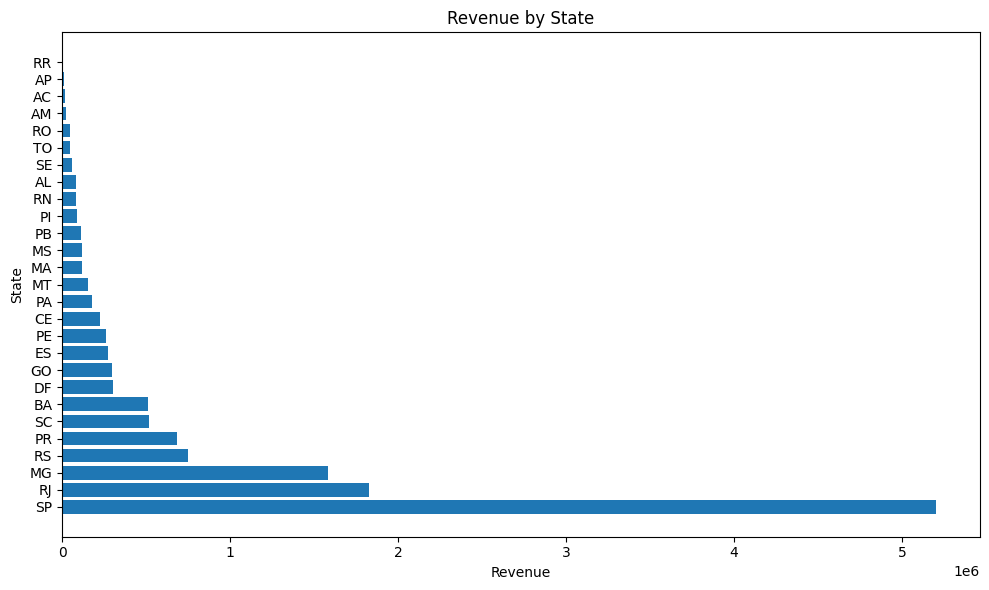

In [137]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.barh(
    states_revenue["customer_state"],
   states_revenue["totalrevenue"]
)

plt.title("Revenue by State")

plt.xlabel("Revenue")

plt.ylabel("State")

plt.tight_layout()

plt.show()

## Visualization Insight
The visualization shows that São Paulo (SP) generates significantly higher revenue compared to all other states, making it the strongest market in the dataset. Rio de Janeiro (RJ) and Minas Gerais (MG) are the next highest revenue-generating states, but their revenue is still much lower than SP. This indicates that customer demand and sales activity are highly concentrated in a few major states. Revenue here is based on product price only (excluding freight), so values are slightly lower than in the Power BI dashboard.

## Business Question 3: Who are the top-performing sellers?

This query identifies the top-performing sellers based on total revenue and number of orders.

In [138]:
query = """
SELECT oi.seller_id, SUM(price) AS total_revenue, COUNT(DISTINCT oi.order_id) AS order_count
FROM sellers sel
JOIN order_items oi
ON sel.seller_id = oi.seller_id
GROUP BY oi.seller_id
ORDER BY total_revenue desc
LIMIT 10
"""

sellers_revenue = pd.read_sql(query, engine)
sellers_revenue

,seller_id,total_revenue,order_count
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1132
1,53243585a1d6dc2643021fd1853d8905,222776.05,358
2,4a3ca9315b744ce9f8e9374361493884,200472.92,1806
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,585
4,7c67e1448b00f6e969d365cea6b010ab,187923.89,982
5,7e93a43ef30c4f03f38b393420bc753a,176431.87,336
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1314
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1160
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,915
9,955fee9216a65b617aa5c0531780ce60,135171.70,1287


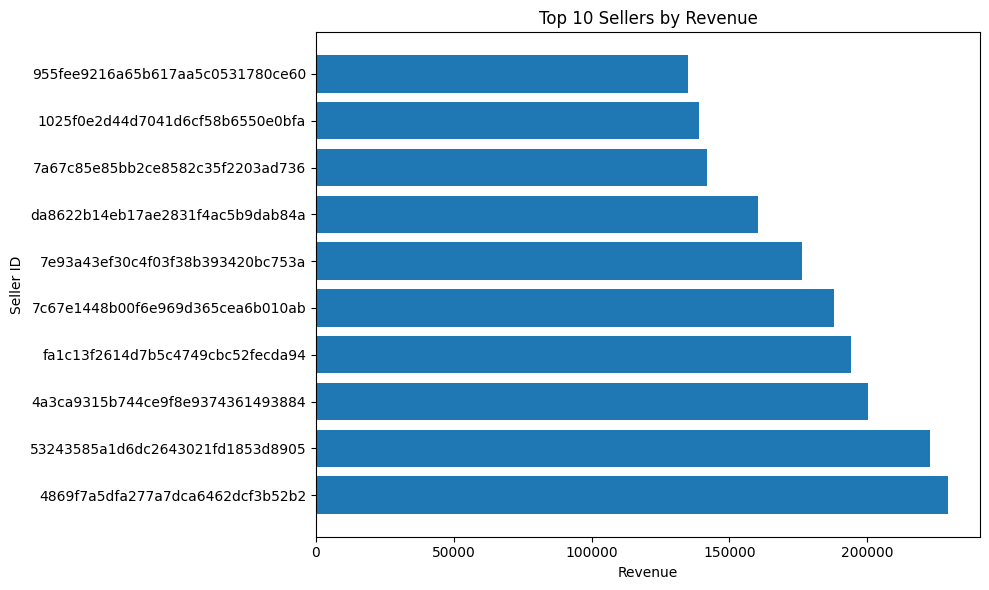

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.barh(
    sellers_revenue["seller_id"],
    sellers_revenue["total_revenue"]
)

plt.title("Top 10 Sellers by Revenue")

plt.xlabel("Revenue")

plt.ylabel("Seller ID")

plt.tight_layout()

plt.show()

## Visualization Insight

The visualization shows that a small group of sellers generates significantly higher revenue compared to others. The top seller produced the highest total revenue, followed closely by several other high-performing sellers. This indicates that sales performance is concentrated among a limited number of sellers within the marketplace.

## Business Question 4: What payment methods are most popular?

This query analyzes total revenue generated by each payment method.

In [140]:
query = """
  SELECT payment_type,COUNT(DISTINCT order_id) AS Nooforder, SUM(payment_value) AS total_revenue
  FROM order_payments
  GROUP BY payment_type
  ORDER BY total_revenue DESC
  """
payments = pd.read_sql(query, engine)

payments

,payment_type,nooforder,total_revenue
0,credit_card,76505,12542084.19
1,boleto,19784,2869361.27
2,voucher,3866,379436.87
3,debit_card,1528,217989.79
4,not_defined,3,0.00


In [141]:
payments = payments[payments["payment_type"] != "not_defined"]

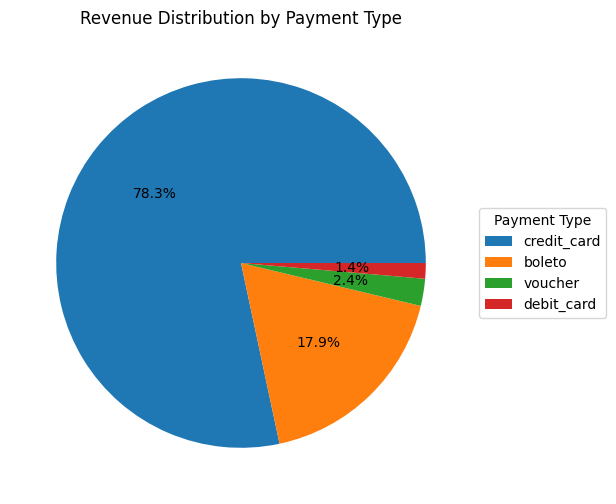

In [142]:
plt.figure(figsize=(8,6))

plt.pie(
    payments["total_revenue"],
    autopct='%1.1f%%'
)

plt.legend(
    payments["payment_type"],
    title="Payment Type",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Revenue Distribution by Payment Type")
plt.show()

## Visualization Insight

The pie chart shows that credit cards account for the majority of total payment revenue, contributing more than 78% of all payments. Boleto is the second most popular payment method, while voucher and debit card represent only a small percentage of total revenue.

## Business Question 5: How long does delivery usually take?

This query analyzes the average delivery time between order purchase and customer delivery date for each customer state.

In [143]:
query = """
SELECT cu.customer_state,
AVG(DATE_PART ('day', order_delivered_customer_date - order_purchase_timestamp)) AS Avgdeliverydays
FROM orders o
JOIN customers cu
ON o.customer_id = cu.customer_id
WHERE order_delivered_customer_date IS NOT NULL
GROUP BY cu.customer_state
"""
delivered_date = pd.read_sql(query, engine)

delivered_date

,customer_state,avgdeliverydays
0,AC,20.637500
1,AL,24.040302
2,AM,25.986207
3,AP,26.731343
4,BA,18.866400
5,CE,20.817826
6,DF,12.509135
7,ES,15.331830
8,GO,15.150741
9,MA,21.117155


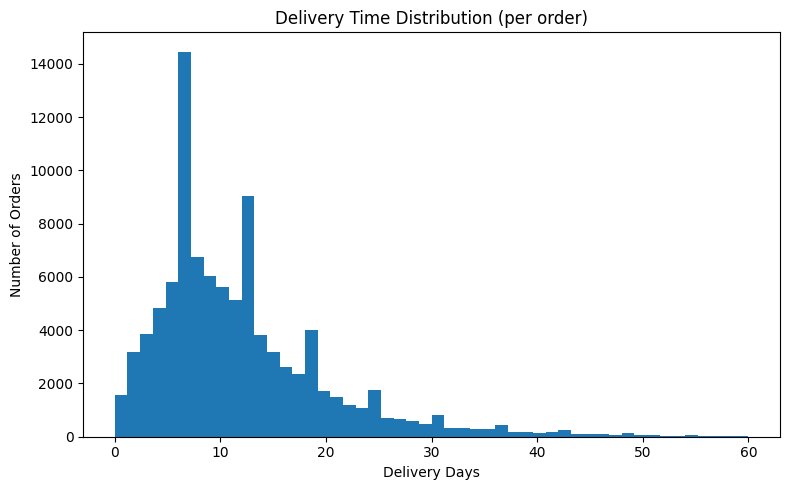

Average: 12.1 days | Median: 10 days


In [144]:
query = """
SELECT DATE_PART('day', order_delivered_customer_date - order_purchase_timestamp) AS delivery_days
FROM orders
WHERE order_delivered_customer_date IS NOT NULL
"""
delivery_days = pd.read_sql(query, engine)

plt.figure(figsize=(8,5))
plt.hist(delivery_days["delivery_days"], bins=50, range=(0, 60))
plt.title("Delivery Time Distribution (per order)")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

print(f"Average: {delivery_days['delivery_days'].mean():.1f} days | Median: {delivery_days['delivery_days'].median():.0f} days")

## Visualization Insight

Most orders arrive within one to two weeks (median 10 days, average 12.1 days). The distribution has a long right tail, with some orders taking 30 days or more, which pulls the average above the median.

In [145]:
delivered_date.sort_values(by='avgdeliverydays', ascending=False).head(10)

,customer_state,avgdeliverydays
21,RR,28.975610
3,AP,26.731343
2,AM,25.986207
1,AL,24.040302
13,PA,23.316068
9,MA,21.117155
24,SE,21.029851
5,CE,20.817826
0,AC,20.637500
14,PB,19.953578


## Insight

States such as RR, AP, and AM have the longest average delivery times, suggesting that geographic distance and logistics infrastructure may impact shipping performance.

## Business Question 6: Are late deliveries affecting customer reviews?

This query compares average customer review scores between on-time and late deliveries to measure the impact of delivery delays on customer satisfaction.

In [146]:
query = """
SELECT
  orr.review_score,
  CASE
    WHEN order_delivered_customer_date IS NULL THEN 'Not Delivered'
    WHEN order_delivered_customer_date > order_estimated_delivery_date THEN 'Late'
    ELSE 'On Time'
  END AS delivery_status
FROM orders o
JOIN order_reviews orr
  ON o.order_id = orr.order_id
"""

delivery_box = pd.read_sql(query, engine)
delivery_box.head()

,review_score,delivery_status
0,4,On Time
1,4,On Time
2,5,On Time
3,5,On Time
4,5,On Time


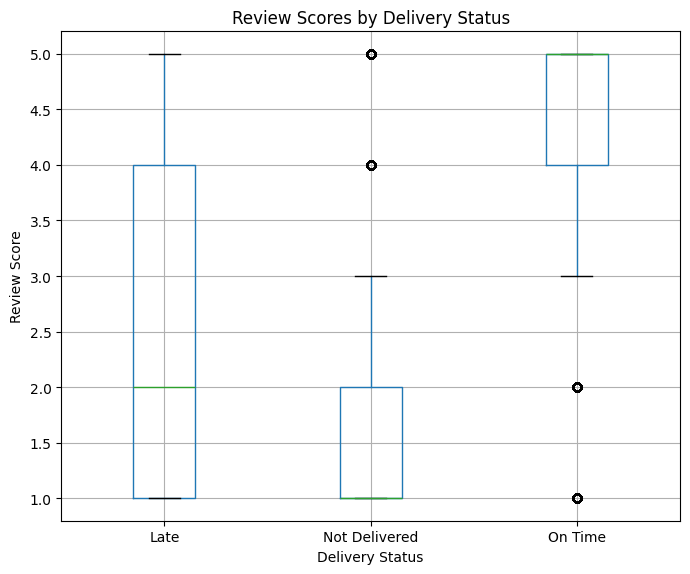

In [147]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7,6))
delivery_box.boxplot(column="review_score", by="delivery_status", ax=ax)
ax.set_title("Review Scores by Delivery Status")
fig.suptitle("")
ax.set_xlabel("Delivery Status")
ax.set_ylabel("Review Score")
plt.tight_layout()
plt.show()

Visualization Insight:

The boxplot shows a clear drop in review scores as delivery performance gets worse. On-time orders have a median score of 5, with most reviews between 4 and 5. Late orders fall to a median of 2 and are spread across the whole 1–5 range, showing a much less consistent experience. Orders that were never delivered have a median of 1. Delivery delays are strongly linked to lower customer satisfaction.

In [148]:
engine.dispose()
query = """
SELECT
  CASE
    WHEN order_delivered_customer_date IS NULL THEN 'Not Delivered'
    WHEN order_delivered_customer_date > order_estimated_delivery_date THEN 'Late'
    ELSE 'On Time'
  END AS delivery_status,
  ROUND(AVG(orr.review_score)::numeric, 2) AS avg_reviewscore,
  COUNT(*) AS reviews
FROM orders o
JOIN order_reviews orr
  ON o.order_id = orr.order_id
GROUP BY delivery_status
ORDER BY avg_reviewscore DESC
"""

review_by_status = pd.read_sql(query, engine)
review_by_status

,delivery_status,avg_reviewscore,reviews
0,On Time,4.29,88658
1,Late,2.57,7701
2,Not Delivered,1.76,2865


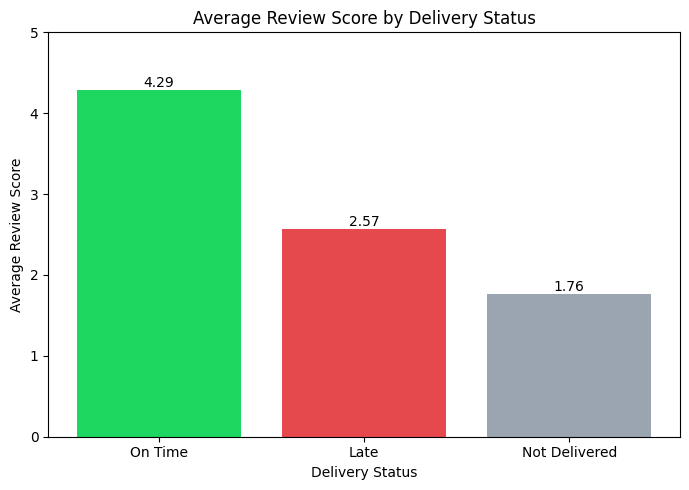

In [149]:
colors = {"On Time": "#1ED760", "Late": "#E5484D", "Not Delivered": "#9AA5B1"}

plt.figure(figsize=(7,5))
bars = plt.bar(review_by_status["delivery_status"],
               review_by_status["avg_reviewscore"],
               color=[colors[s] for s in review_by_status["delivery_status"]])
plt.bar_label(bars, fmt="%.2f")
plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

## Visualization Insight

On-time orders average 4.29 stars, late orders drop to 2.57, and orders that were never delivered score only 1.76. Late delivery cuts the average review score by about 40%, so logistics performance directly drives customer satisfaction.

# Business Question 7: Which product categories receive the best and worst reviews?

This query compares average review scores across product categories to find the best- and worst-rated ones. Only categories with at least 100 reviews are included, so small categories can’t top the list by chance.

In [150]:
engine.dispose()
query = """
SELECT
    ct.product_category_name_english AS category,
    COUNT(r.review_score) AS review_count,
    ROUND(AVG(r.review_score)::numeric, 2) AS avg_review,
    MIN(r.review_score) AS min_review,
    MAX(r.review_score) AS max_review
FROM order_reviews r
JOIN order_items oi
    ON r.order_id = oi.order_id
JOIN products p
    ON oi.product_id = p.product_id
JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name
GROUP BY ct.product_category_name_english
HAVING COUNT(r.review_score) >= 100
ORDER BY avg_review DESC;
"""

categoryR = pd.read_sql(query, engine)
categoryR

,category,review_count,avg_review,min_review,max_review
0,books_general_interest,549,4.45,1,5
1,books_technical,266,4.37,1,5
2,food_drink,279,4.32,1,5
3,luggage_accessories,1088,4.32,1,5
4,fashion_shoes,261,4.23,1,5
5,food,495,4.22,1,5
6,stationery,2507,4.19,1,5
7,pet_shop,1939,4.19,1,5
8,computers,200,4.18,1,5
9,home_appliances,806,4.17,1,5


## Insight:
Of the 52 categories with at least 100 reviews, Books General Interest (4.45), Books Technical (4.37) and Food & Drink (4.32) receive the highest average scores. The lowest-rated are Office Furniture (3.49), Fashion Male Clothing (3.64) and Fixed Telephony (3.68).

Office Furniture stands out because it combines a low score with high volume (1,687 reviews), so this is a consistent problem rather than a small-sample effect. Bulky, heavy items like furniture are harder to ship, which may point to delivery or product-condition issues worth investigating.

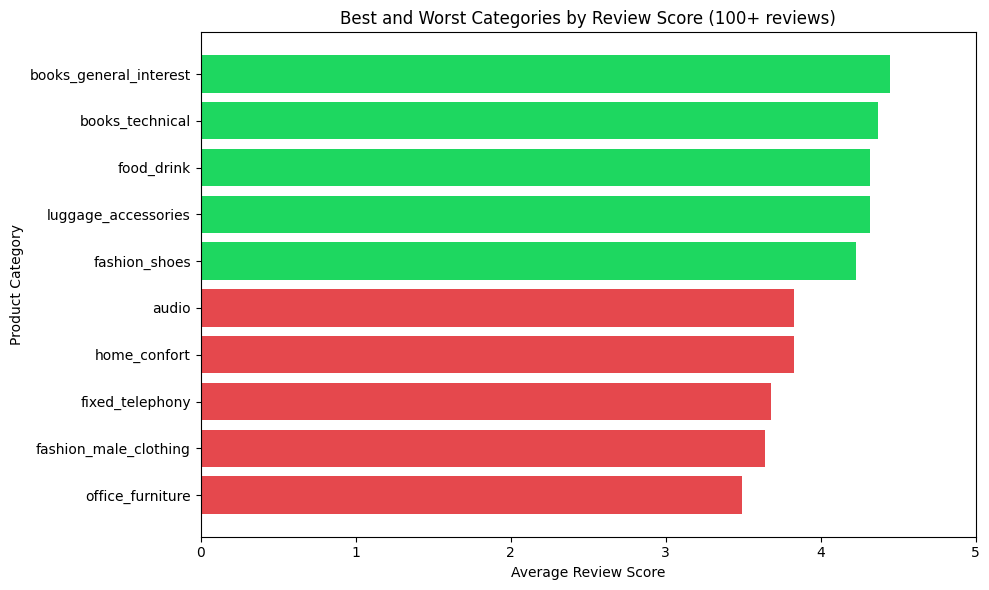

In [151]:
top_bottom = pd.concat([categoryR.head(5), categoryR.tail(5)])
colors = ["#1ED760"] * 5 + ["#E5484D"] * 5

plt.figure(figsize=(10,6))
plt.barh(top_bottom["category"], top_bottom["avg_review"], color=colors)
plt.gca().invert_yaxis()
plt.title("Best and Worst Categories by Review Score (100+ reviews)")
plt.xlabel("Average Review Score")
plt.ylabel("Product Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

# Visualization Insight:
The chart shows a clear gap between the best-rated categories (green), led by Books General Interest at 4.45, and the worst-rated (red), with Office Furniture lowest at 3.49. Even the weakest categories average above 3.4, but the roughly one-point gap shows which product areas need attention.

# Business Question 8: What is the average order value (AOV)?

This query calculates the Average Order Value (AOV) by dividing total revenue by the total number of unique orders to measure average customer spending per order.

In [152]:
query = """
  SELECT SUM(oi.price)/ COUNT(DISTINCT o.order_id) AS AOV
  FROM orders AS o
  JOIN order_items AS oi
  ON o.order_id = oi.order_id
    """
avegvalue = pd.read_sql(query, engine)
avegvalue

,aov
0,137.754076


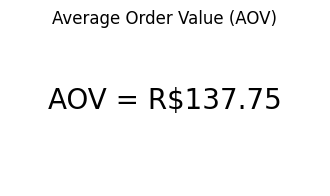

In [153]:
plt.figure(figsize=(4,2))
plt.text(0.5, 0.5,
         f"AOV = R\\${avegvalue['aov'][0]:.2f}",
         fontsize=20,
         ha="center")
plt.axis("off")
plt.title("Average Order Value (AOV)")
plt.show()

The average order value is about **R\$ 137.75** based on product price only. The Power BI dashboard shows **R\$ 161** because it uses total payment value, which includes freight.

# Business Question 9: Which cities have the most customers?

This query analyzes customer distribution across cities to identify the cities with the highest number of customers and determine key customer markets.

In [154]:
query = """
  SELECT customer_city, COUNT(DISTINCT customer_unique_id) AS no_of_customers
  FROM customers cs
  GROUP BY customer_city
  ORDER BY no_of_customers DESC
  LIMIT 10
    """

customers_no = pd.read_sql(query, engine)
customers_no

,customer_city,no_of_customers
0,sao paulo,14984
1,rio de janeiro,6620
2,belo horizonte,2672
3,brasilia,2069
4,curitiba,1465
5,campinas,1398
6,porto alegre,1326
7,salvador,1209
8,guarulhos,1153
9,sao bernardo do campo,908


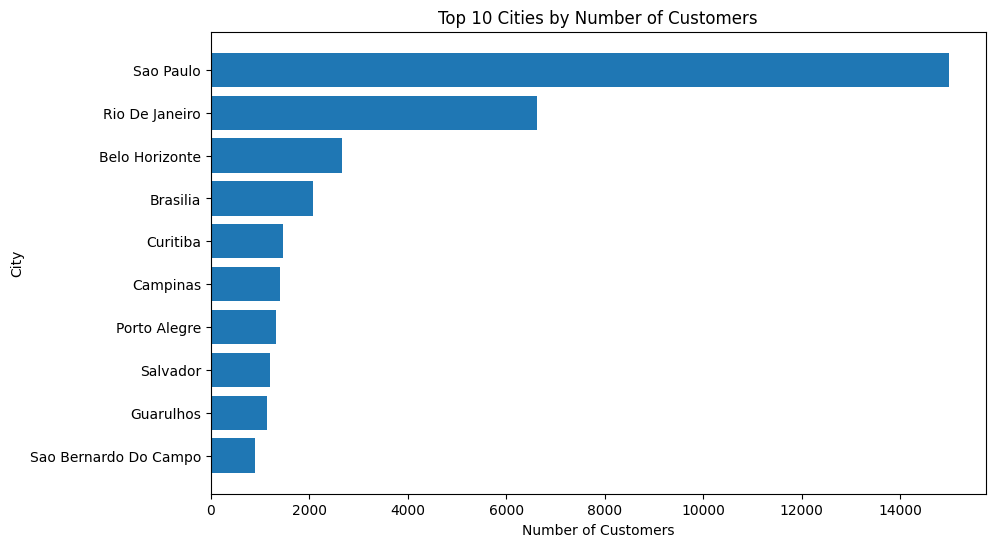

In [155]:
top10 = customers_no.head(10)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.barh(
    top10["customer_city"].str.title(),
    top10["no_of_customers"]
)

plt.title("Top 10 Cities by Number of Customers")

plt.xlabel("Number of Customers")

plt.ylabel("City")

plt.gca().invert_yaxis()

plt.show()

# Visualization Insight:
São Paulo dominates the customer base with about 15,000 unique customers, more than twice as many as Rio de Janeiro (6,620). After the top two, the numbers drop sharply, with every other city under 2,700, so customers are concentrated in a few major metropolitan areas.

# Business Question 10: What factors influence product price and freight cost?

This query analyzes the relationship between product price, freight cost, product weight, and product dimensions to identify factors that impact shipping expenses and product pricing.

In [156]:
query = """
SELECT oi.price, oi.freight_value,p.product_weight_g, p.product_length_cm,
    p.product_height_cm, p.product_width_cm
FROM products AS p
JOIN order_items AS oi
ON p.product_id = oi.product_id
"""

shipping = pd.read_sql(query, engine)

shipping

,price,freight_value,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,58.90,13.29,650.0,28.0,9.0,14.0
1,239.90,19.93,30000.0,50.0,30.0,40.0
2,199.00,17.87,3050.0,33.0,13.0,33.0
3,12.99,12.79,200.0,16.0,10.0,15.0
4,199.90,18.14,3750.0,35.0,40.0,30.0
...,...,...,...,...,...,...
112645,299.99,43.41,10150.0,89.0,15.0,40.0
112646,350.00,36.53,8950.0,45.0,26.0,38.0
112647,99.90,16.95,967.0,21.0,24.0,19.0
112648,55.99,8.72,100.0,20.0,20.0,20.0


In [157]:
shipping.corr(numeric_only=True)

,price,freight_value,product_weight_g,product_length_cm,product_height_cm,product_width_cm
price,1.000000,0.414204,0.338819,0.145811,0.223602,0.172467
freight_value,0.414204,1.000000,0.610420,0.309086,0.391831,0.323777
product_weight_g,0.338819,0.610420,1.000000,0.460919,0.583277,0.506609
product_length_cm,0.145811,0.309086,0.460919,1.000000,0.192895,0.532537
product_height_cm,0.223602,0.391831,0.583277,0.192895,1.000000,0.281224
product_width_cm,0.172467,0.323777,0.506609,0.532537,0.281224,1.000000


# Visualization Insight:
The scatter plot shows a positive relationship between product weight and freight cost. In general, heavier products tend to have higher shipping costs, although some variations and outliers indicate that other factors such as product dimensions and delivery distance may also influence freight charges.

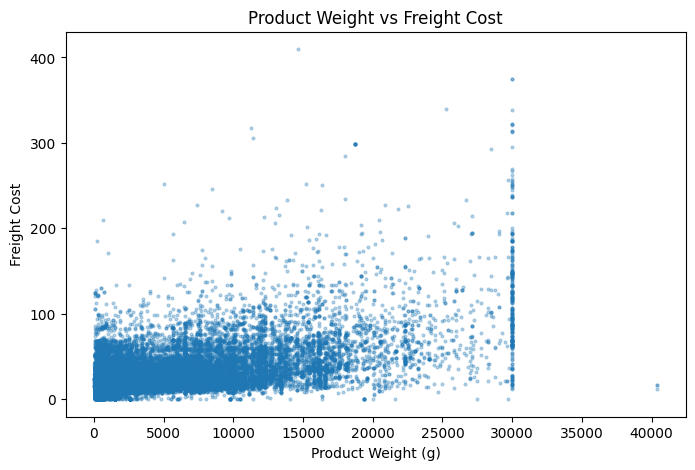

In [158]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(
    shipping["product_weight_g"],
    shipping["freight_value"], s=4, alpha=0.3
)

plt.title("Product Weight vs Freight Cost")

plt.xlabel("Product Weight (g)")

plt.ylabel("Freight Cost")

plt.show()

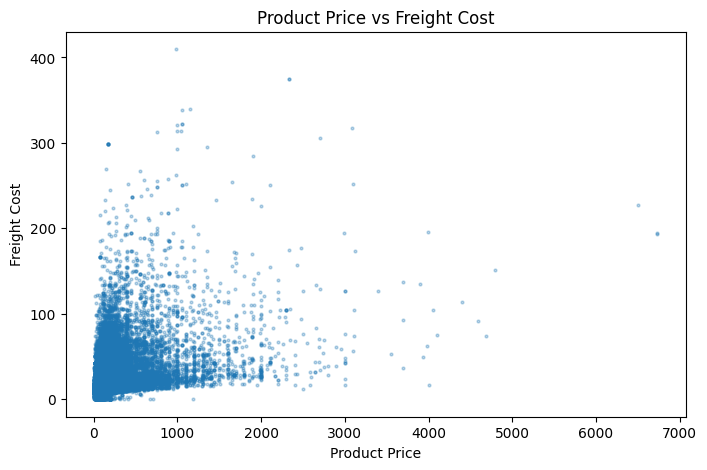

In [159]:
plt.figure(figsize=(8,5))

plt.scatter(
    shipping["price"],
    shipping["freight_value"], s=4, alpha=0.3
)

plt.title("Product Price vs Freight Cost")

plt.xlabel("Product Price")

plt.ylabel("Freight Cost")

plt.show()

# Visualization Insight:
The scatter plot shows a weak positive relationship between product price and freight cost. Higher-priced products may sometimes have higher shipping costs, but the relationship is not strong, suggesting that freight charges are influenced more by product weight and size than by product price alone. Most products are priced under R\$1,000, and even expensive items often ship for under R\$100, which confirms that weight and size matter more than price.